# Аномалии потребления воды — тестовое задание «Вавиот Азия»

**Автор:** Диас Ахметбек · Telegram @akhmetbekdi

**Данные:** 3 000 приборов учёта, 693 443 суточных показания (01.10.2025 – 01.10.2026), 34 009 событий.

**Как устроен ноутбук** — каждый шаг можно перезапустить сверху вниз (`Run All`), все пороги вынесены в один блок `ПОРОГИ`:

0. Загрузка и проверка данных
1. Очистка: шум float, выбросы показаний
2. Суточное потребление
3. Пункты 1–8 задания
4. Итог: кого проверять в первую очередь

Данные (`pokazaniya.csv`, `pribory.csv`, `sobytiya.csv`) кладутся в папку `data/` рядом с ноутбуком.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path
import warnings
warnings.filterwarnings('ignore', category=UserWarning)

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 20)
DATA = Path('data')

# ---- ПОРОГИ (все в одном месте) ----
ROUND_M3        = 3      # точность показаний: 0.001 м³ = 1 литр
OUTLIER_MIN     = 2      # выброс: показание отличается от медианы 9 соседних больше чем на max(2 м³,
OUTLIER_X       = 20     #         20 обычных суток этого прибора)
BIT_STEP        = 327.68 # 2^15 * 0.01 м³ — шаг «битовой» ошибки (см. находки)
QMAX_DAY        = 75     # физический предел DN15: Q4 = 3.125 м³/ч * 24 ч = 75 м³/сут
SPIKE_ABS       = 3.0    # всплеск: > 3 м³ за сутки (≈ в 25 раз больше среднего дня по базе)
SPIKE_REL       = 10     # всплеск: > 10x обычного дня прибора ...
SPIKE_REL_MIN   = 0.5    # ... и при этом не меньше 0.5 м³ (чтобы 0.01 -> 0.1 не считалось)
LEAK_DAYS       = 90     # утечка: >= 90 суток подряд без единого «нулевого» дня
LEAK_FLOOR      = 0.05   # ... и даже «тихие» дни (5-й перцентиль) >= 50 л/сут
ZERO_DAYS       = 30     # ноль: >= 30 суток подряд расход 0, а пакеты идут
STEP_RATIO      = 3      # ступенька: медиана после / до (или наоборот) >= 3
STEP_MIN_LEVEL  = 0.1    # ... верхний уровень >= 0.1 м³/сут
STEP_MIN_DAYS   = 30     # ... и на каждой стороне >= 30 дней данных

# Палитра графиков (проверенная на дальтонизм)
C_BLUE, C_ORANGE, C_AQUA, C_RED, C_GRAY = '#2a78d6', '#eb6834', '#1baf7a', '#e34948', '#8a8984'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.6,
                     'axes.edgecolor': '#8a8984', 'axes.axisbelow': True, 'axes.titlesize': 11, 'axes.titleweight': 'bold'})

## 0. Загрузка

In [2]:
P = pd.read_csv(DATA/'pokazaniya.csv', sep=';', dtype={'anon_id': str}, parse_dates=['data'])
D = pd.read_csv(DATA/'pribory.csv',    sep=';', dtype={'anon_id': str})
S = pd.read_csv(DATA/'sobytiya.csv',   sep=';', dtype={'anon_id': str}, parse_dates=['data'])
P = P.sort_values(['anon_id', 'data']).reset_index(drop=True)

print(f'показаний: {len(P):,}  приборов: {P.anon_id.nunique():,}  период: {P.data.min():%d.%m.%Y} – {P.data.max():%d.%m.%Y}')
print('дубликатов (прибор+дата):', P.duplicated(['anon_id', 'data']).sum(), '| пропусков в показаниях:', P.pokazanie.isna().sum())
print('пакетов за сутки: min', P.paketov_za_sutki.min(), '— т.е. каждая строка = прибор был на связи')
print(S.sobytie.value_counts().to_string())

показаний: 693,443  приборов: 3,000  период: 01.10.2025 – 01.10.2026
дубликатов (прибор+дата): 0 | пропусков в показаниях: 0
пакетов за сутки: min 1 — т.е. каждая строка = прибор был на связи
sobytie
магнит    33365
сброс       374
Холл        270


## 1. Очистка

**1a. Шум float.** Показания вида `47.585833` после вычитания дают «отрицательный» расход `-3e-13` — это ошибка округления, а не реальный откат. Округляем до 0.001 м³ (1 литр, разрешение счётчика). Это убирает **311** ложных «отрицательных» случаев.

**1b. Выбросы показаний.** Иногда приходит одно-два «мусорных» показания (например `314.83 → 3149.60 → 315.12` или `3.81 → 38.2 → 3.84` — сдвиг запятой), после которых счётчик возвращается на прежний уровень. Накопительный счётчик не может «сходить вверх и вернуться», поэтому показание считаем выбросом, если оно отличается от медианы 9 соседних показаний этого же прибора больше чем на max(2 м³, 20 обычных суток прибора). Настоящий рост (даже большой) не попадает под фильтр: после него показания остаются на новом уровне, и медиана «переезжает» вместе с ними. Такие точки не участвуют в расчёте потребления, но учитываются в пунктах 1 и 3 как ошибки данных.

In [3]:
P['pokazanie'] = P['pokazanie'].round(ROUND_M3)
med9 = P.groupby('anon_id')['pokazanie'].transform(lambda x: x.rolling(9, center=True, min_periods=3).median())
# «обычные сутки» прибора — медиана положительных приращений (устойчива к сбоям)
_d = P.groupby('anon_id')['pokazanie'].diff()
typ = _d.where(_d > 0).groupby(P.anon_id).transform('median').fillna(0)
thr = np.maximum(OUTLIER_MIN, OUTLIER_X * typ)
# и главное — показание ломает монотонность: после него есть показание ниже, или до него было выше
grp = P.groupby('anon_id')['pokazanie']
fut_min  = grp.transform(lambda x: x[::-1].rolling(4, min_periods=1).min()[::-1].shift(-1))
past_max = grp.transform(lambda x: x.rolling(4, min_periods=1).max().shift(1))
nonmono = (P['pokazanie'] > fut_min + 0.001) | (P['pokazanie'] < past_max - 0.001)
P['vybros'] = ((P['pokazanie'] - med9).abs() > thr) & nonmono

# «сырые» разности (для пунктов 1 и 3 — там нужны именно ошибки)
P['gap']  = P.groupby('anon_id').data.diff().dt.days
P['diff'] = P.groupby('anon_id').pokazanie.diff().round(ROUND_M3)
P['prev_vybros'] = P.groupby('anon_id').vybros.shift(1).fillna(False).astype(bool)
print('выбросов показаний:', P.vybros.sum(), 'у приборов:', P.loc[P.vybros, 'anon_id'].nunique())

выбросов показаний: 527 у приборов: 52


## 2. Суточное потребление

`расход = показание(день) − показание(предыдущий день)`.

* Если между показаниями пропуск (`gap` > 1 дня — прибор не вышел на связь), разность делится на число дней → средний суточный расход `rate`. Для поиска «нулевых» суток и непрерывных серий берутся **только соседние дни** (`gap == 1`), иначе нельзя сказать, что было в пропущенный день.
* **Валидный расход:** `0 ≤ rate ≤ 75 м³/сут` (выше — физически невозможно для DN15, см. п.3).

In [4]:
C = P[~P.vybros].copy()
C['gap']  = C.groupby('anon_id').data.diff().dt.days
C['d']    = C.groupby('anon_id').pokazanie.diff().round(ROUND_M3)
C['rate'] = C['d'] / C['gap']
C = C.dropna(subset=['d'])
C['valid'] = (C['d'] >= 0) & (C['rate'] <= QMAX_DAY)
V  = C[C.valid]                 # все валидные интервалы
V1 = V[V.gap == 1].copy()       # валидные соседние сутки

print(f'интервалов: {len(C):,}, валидных: {len(V):,} ({len(V)/len(C):.1%}), из них соседних суток: {len(V1):,}')
print(f'доля строк с пропуском перед ними: {(P.gap > 1).mean():.1%}')
print(f'средний расход: {V1.d.mean():.3f} м³/сут, медиана {V1.d.median():.3f}, 99-й перцентиль {V1.d.quantile(.99):.2f}')

# приборы с ошибками данных (выбросы или > 75 м³/сут) — их всплески не считаем «водой»
_raw_rate = P['diff'] / P['gap']
err_ids = set(P.loc[P.vybros, 'anon_id']) | set(P.loc[_raw_rate > QMAX_DAY, 'anon_id'])
print('приборов с ошибками данных:', len(err_ids))

интервалов: 689,916, валидных: 689,702 (100.0%), из них соседних суток: 615,742
доля строк с пропуском перед ними: 10.7%
средний расход: 0.124 м³/сут, медиана 0.036, 99-й перцентиль 1.13
приборов с ошибками данных: 60


In [5]:
# вспомогательная функция: серии подряд идущих суток, где выполняется условие
def longest_runs(df, cond):
    """Для каждого прибора — самая длинная серия соседних суток (gap==1), где cond == True.
    Возвращает: длину, дату начала, дату конца."""
    x = df[['anon_id', 'data', 'gap', 'd']].copy()
    x['ok'] = cond.values & (x.gap == 1).values
    x['grp'] = (~x.ok).groupby(x.anon_id).cumsum()          # номер серии внутри прибора
    r = (x[x.ok].groupby(['anon_id', 'grp'])
           .agg(days=('data', 'size'), start=('data', 'min'), end=('data', 'max'),
                p5=('d', lambda s: s.quantile(.05)), dmin=('d', 'min'), dmed=('d', 'median')))
    return r.sort_values('days').groupby(level=0).tail(1).droplevel(1)

dev = D.set_index('anon_id')
# «обычный день» прибора = медиана ненулевых валидных суток (если таких >= 30)
pos = V1[V1.d > 0].groupby('anon_id').d.agg(['median', 'size'])
usual = pos.loc[pos['size'] >= 30, 'median']

## Пункт 1. Отрицательный расход

**Критерий:** показание меньше предыдущего хотя бы на 1 литр (после округления, т.е. без float-шума).

Разбираем каждый случай по причине:
* **битовая ошибка** — скачок ровно на ±327.68·k м³ (подробно в находке 1);
* **возврат после выброса** — предыдущее показание было «мусорным», счётчик вернулся на свой уровень;
* **сброс/замена** — показание упало почти до 0 (замена прибора или обнуление);
* **малый откат** до 1 м³ — обратный ток воды / гидроудар / дребезг датчика;
* **прочее** — крупные необъяснённые падения.

In [6]:
neg = P[P['diff'] < 0].copy()
k = neg['diff'] / BIT_STEP
neg['prichina'] = np.select(
    [(neg['diff'].abs() > 300) & ((k - k.round()).abs() * BIT_STEP < 1.5),
     neg.prev_vybros,
     (neg.pokazanie < 1) & (neg.pokazanie - neg['diff'] > 5),
     neg['diff'] > -1],
    ['битовая ошибка ±327.68·k', 'возврат после выброса', 'сброс/замена (упал до ~0)', 'малый откат < 1 м³'],
    default='прочее крупное падение')

n1 = neg.groupby('prichina').agg(sluchaev=('diff', 'size'), priborov=('anon_id', 'nunique'),
                                 primery=('anon_id', lambda s: ', '.join(s.value_counts().index[:4])))
print(f'Отрицательный расход: {len(neg)} случаев у {neg.anon_id.nunique()} приборов')
n1.sort_values('sluchaev', ascending=False)

Отрицательный расход: 269 случаев у 102 приборов


,sluchaev,priborov,primery
prichina,,,
битовая ошибка ±327.68·k,135,52,"2030325, 8190741, 9487974, 2351232"
малый откат < 1 м³,98,56,"7931977, 3917499, 2735490, 1120133"
возврат после выброса,23,17,"7826125, 1492831, 2519659, 5115252"
прочее крупное падение,7,5,"2647530, 6958101, 2409777, 5317621"
сброс/замена (упал до ~0),6,3,"7826125, 2409777, 8908023"


In [7]:
# связь со «сбросом» из журнала событий
SB = S[S.sobytie == 'сброс'][['anon_id', 'data']].drop_duplicates()
m = neg.merge(SB, on='anon_id', suffixes=('', '_sb'))
m = m[(m.data - m.data_sb).dt.days.abs() <= 3]
print('отрицательных случаев, рядом с которыми (±3 дня) есть событие «сброс»:', m[['anon_id', 'data']].drop_duplicates().shape[0])
neg[neg.prichina == 'малый откат < 1 м³'].sort_values('diff').head(5)[['anon_id', 'data', 'pokazanie', 'diff']]

отрицательных случаев, рядом с которыми (±3 дня) есть событие «сброс»: 16


,anon_id,data,pokazanie,diff
393391,6025274,2026-02-27,1927.634,-0.863
682283,9875716,2026-02-11,904.851,-0.619
182574,3228151,2026-08-28,0.032,-0.502
5749,1063500,2026-08-16,0.032,-0.502
182531,3228151,2026-07-05,0.032,-0.502


## Пункт 2. Всплески расхода за сутки

Считаем только по валидным соседним суткам (без ошибок данных).
* **Абсолютный порог:** > 3 м³ за сутки. Средний день по базе ≈ 0.13 м³, 99-й перцентиль ≈ 1.2 м³ — 3 м³ это ~25 «обычных дней».
* **Относительный порог:** > 10× обычного дня этого прибора (медиана его ненулевых суток) **и** ≥ 0.5 м³ — чтобы скачок с 10 до 100 литров не считался всплеском.
* Приборы с ошибками данных (п.3, находка 1) исключены — у них «всплеск» это сбой, а не вода.

In [8]:
V1['usual'] = V1.anon_id.map(usual)
V1['x_usual'] = V1.d / V1.usual
V1c = V1[~V1.anon_id.isin(err_ids)]
abs_sp = V1c[V1c.d > SPIKE_ABS]
rel_sp = V1c[(V1c.x_usual > SPIKE_REL) & (V1c.d >= SPIKE_REL_MIN)]
both   = V1c[(V1c.d > SPIKE_ABS) & (V1c.x_usual > SPIKE_REL)]
print(f'абсолютные (> {SPIKE_ABS} м³/сут): {len(abs_sp)} суток у {abs_sp.anon_id.nunique()} приборов')
print(f'относительные (> {SPIKE_REL}x обычного и >= {SPIKE_REL_MIN} м³): {len(rel_sp)} суток у {rel_sp.anon_id.nunique()} приборов')
print(f'оба условия сразу: {len(both)} суток у {both.anon_id.nunique()} приборов')
big = V1c.groupby('anon_id').d.median()
print('NB: у', (big > 3).sum(), 'приборов (', ', '.join(big[big > 3].index), ') расход > 3 м³ почти каждый день — это не всплески, а крупный потребитель (общедомовой/коммерческий узел?)')
both.sort_values('x_usual', ascending=False).head(8)[['anon_id', 'data', 'd', 'usual', 'x_usual']].round(3)

абсолютные (> 3.0 м³/сут): 842 суток у 68 приборов
относительные (> 10x обычного и >= 0.5 м³): 534 суток у 140 приборов
оба условия сразу: 90 суток у 35 приборов


NB: у 2 приборов ( 4945470, 9277360 ) расход > 3 м³ почти каждый день — это не всплески, а крупный потребитель (общедомовой/коммерческий узел?)


,anon_id,data,d,usual,x_usual
512482,7626821,2026-02-23,8.400,0.032,262.500
601041,8727125,2026-02-23,29.568,0.168,176.525
593832,8620255,2026-05-05,6.293,0.038,165.605
593749,8620255,2026-02-09,6.111,0.038,160.816
289602,4673022,2026-09-27,4.977,0.038,130.974
593644,8620255,2025-10-27,4.857,0.038,127.816
353545,5540392,2026-05-10,6.810,0.060,113.500
374982,5838414,2025-11-26,3.580,0.037,96.757


## Пункт 3. Нереальные значения

**Физический предел.** У DN15 перегрузочный расход Q4 = 3.125 м³/ч. Даже если открыть всё на максимум и не закрывать сутки — это **75 м³/сут**. Всё, что выше, — не вода, а ошибка данных.

Дополнительно: показание счётчика > 100 000 м³ (квартира за всю жизнь столько не потребит) и «подозрительные» 10–75 м³/сут.

In [9]:
raw = P.dropna(subset=['diff']).copy()
raw['rate'] = raw['diff'] / raw['gap']
unreal = raw[raw.rate > QMAX_DAY]
k = unreal['diff'] / BIT_STEP
unreal = unreal.assign(tip_oshibki=np.select(
    [((k - k.round()).abs() * BIT_STEP < 1.5), unreal.vybros | unreal.prev_vybros],
    ['битовая ошибка +327.68·k', 'выброс показания'], 'прочее'))
print(f'> {QMAX_DAY} м³/сут: {len(unreal)} интервалов у {unreal.anon_id.nunique()} приборов')
print(unreal.groupby('tip_oshibki').anon_id.agg(['size', 'nunique']))
huge = P[P.pokazanie > 1e5]
print('\nпоказания > 100 000 м³:', huge[['anon_id', 'data', 'pokazanie']].to_string(index=False))
sus = V1[(V1.d > 10)]
print(f'\nвалидные, но сомнительные 10–75 м³/сут: {len(sus)} суток у {sus.anon_id.nunique()} приборов (вероятно общедомовые/коммерческие или ошибка)')
unreal.sort_values('rate', ascending=False).drop_duplicates('anon_id').head(8)[['anon_id', 'data', 'pokazanie', 'diff', 'tip_oshibki']]

> 75 м³/сут: 304 интервалов у 57 приборов
                          size  nunique
tip_oshibki                            
битовая ошибка +327.68·k   207       46
выброс показания            89       19
прочее                       8        5

показания > 100 000 м³: anon_id       data   pokazanie
2491162 2026-07-09 3006867.717
2519659 2026-06-05 4273565.187
2519659 2026-06-11 4273565.187
8908023 2026-09-07 2684367.792

валидные, но сомнительные 10–75 м³/сут: 65 суток у 10 приборов (вероятно общедомовые/коммерческие или ошибка)


,anon_id,data,pokazanie,diff,tip_oshibki
125024,2491162,2026-07-09,3006867.717,3005503.868,выброс показания
612215,8908023,2026-09-07,2684367.792,2684039.254,выброс показания
126509,2519659,2026-06-11,4273565.187,4273492.461,выброс показания
98257,2159987,2025-10-17,3149.600,2834.770,выброс показания
535786,7891133,2025-10-17,2360.900,2124.960,выброс показания
616864,8973572,2025-10-17,675.700,608.136,выброс показания
336393,5359103,2026-07-05,1029.980,530.317,выброс показания
86315,2030325,2026-07-20,1307.960,425.916,выброс показания


## Пункт 4. Утечка — прибор «никогда не отдыхает»

В нормальной квартире бывают дни без воды (уехали, на работе, все спят у родных). Утечка (течёт бачок, подтекает кран) даёт **расход каждый день без перерыва**, причём даже в самые «тихие» дни он не падает до нуля.

* **Кандидат:** ≥ 90 соседних суток подряд с расходом > 0.
* **Сильный признак:** то же + «пол» потребления (5-й перцентиль суточного расхода в этой серии) ≥ 50 л/сут — то есть вода идёт постоянно.

Ограничение: по суточным данным утечку нельзя отличить от большой семьи на 100%. Для точности нужен ночной (часовой) расход — его можно получать с приборов, которые шлют 24+ пакета в сутки.

In [10]:
leak = longest_runs(C, (C.d > 0) & C.valid)
leak_cand   = leak[leak.days >= LEAK_DAYS]
leak_strong = leak_cand[leak_cand.p5 >= LEAK_FLOOR]
print(f'кандидаты (>= {LEAK_DAYS} суток без нуля): {len(leak_cand)}')
print(f'сильный признак (+ «пол» >= {LEAK_FLOOR*1000:.0f} л/сут): {len(leak_strong)}')
print(f'жёстко (каждый день >= 100 л): {(leak_cand.dmin >= 0.1).sum()}')
leak_strong.sort_values(['p5'], ascending=False).head(10).round(3)

кандидаты (>= 90 суток без нуля): 322
сильный признак (+ «пол» >= 50 л/сут): 155
жёстко (каждый день >= 100 л): 29


,days,start,end,p5,dmin,dmed
anon_id,,,,,,
1606847,120,2026-03-23,2026-07-20,1.219,0.766,1.684
5754693,216,2025-10-02,2026-05-05,0.990,0.754,1.435
1944961,213,2025-10-02,2026-05-02,0.874,0.003,1.327
6383784,213,2025-10-02,2026-05-02,0.620,0.070,0.900
3965367,92,2026-03-13,2026-06-12,0.530,0.321,0.998
5198033,113,2026-01-16,2026-05-08,0.440,0.370,0.630
7656457,114,2026-03-24,2026-07-15,0.415,0.014,0.690
7784695,201,2026-03-14,2026-09-30,0.378,0.153,0.565
5088345,123,2025-11-16,2026-03-18,0.372,0.060,0.609


## Пункт 5. Нулевое потребление при живом приборе

**Критерий:** ≥ 30 соседних суток подряд расход ровно 0, при этом прибор каждый день на связи (строка есть только если пришёл хотя бы 1 пакет).

Делим на две группы — они означают разное:
* **никогда не потреблял** (< 100 л за весь год) → пустая квартира / перекрыт стояк / прибор не врезан;
* **потреблял, потом встал** → уехали надолго **или счётчик застрял/остановлен** — это кандидаты на проверку.

In [11]:
zero = longest_runs(C, C.d == 0)
zero = zero[zero.days >= ZERO_DAYS].copy()
total = V.groupby('anon_id').d.sum()
zero['vsego_za_god'] = zero.index.map(total).fillna(0)
zero['gruppa'] = np.where(zero.vsego_za_god < 0.1, 'никогда не потреблял', 'потреблял, потом встал')  # < 100 л за год = практически ноль
pk = C.merge(zero[['start', 'end']], left_on='anon_id', right_index=True)
pk = pk[(pk.data >= pk.start) & (pk.data <= pk.end)]
print(f'>= {ZERO_DAYS} суток нуля при живой связи: {len(zero)} приборов; >= 60 суток: {(zero.days >= 60).sum()}')
print('медиана пакетов в сутки в эти дни:', pk.paketov_za_sutki.median())
print(zero.groupby('gruppa').days.agg(['size', 'median', 'max']))
zero[zero.gruppa == 'потреблял, потом встал'].sort_values('days', ascending=False).head(8)

>= 30 суток нуля при живой связи: 694 приборов; >= 60 суток: 348
медиана пакетов в сутки в эти дни: 5.0
                        size  median  max
gruppa                                   
никогда не потреблял     431    67.0  364
потреблял, потом встал   263    52.0  331


,days,start,end,p5,dmin,dmed,vsego_za_god,gruppa
anon_id,,,,,,,,
5374718,331,2025-11-05,2026-10-01,0.0,0.0,0.0,1.391,"потреблял, потом встал"
4954627,286,2025-12-19,2026-09-30,0.0,0.0,0.0,0.106,"потреблял, потом встал"
1201898,274,2025-10-02,2026-07-02,0.0,0.0,0.0,0.185,"потреблял, потом встал"
3025088,251,2025-10-24,2026-07-01,0.0,0.0,0.0,2.638,"потреблял, потом встал"
3343211,247,2025-10-29,2026-07-02,0.0,0.0,0.0,0.114,"потреблял, потом встал"
9302752,194,2026-03-22,2026-10-01,0.0,0.0,0.0,7.294,"потреблял, потом встал"
4530662,194,2026-03-22,2026-10-01,0.0,0.0,0.0,8.086,"потреблял, потом встал"
1063500,184,2025-12-28,2026-06-29,0.0,0.0,0.0,0.504,"потреблял, потом встал"


## Пункт 6. Ступенька — резкое устойчивое изменение уровня

Простой вариант из задания — сравнить среднее первой и второй половины периода. Но ступенька может быть в любой день, а среднее портит один всплеск. Поэтому:
* для каждого прибора перебираем точку разреза (≥ 30 дней данных с каждой стороны);
* сравниваем **медианы** до и после (медиана устойчива к единичным всплескам);
* ступенька, если уровни различаются ≥ 3 раз и верхний уровень ≥ 0.1 м³/сут.

Тип ступеньки важен: **0 → N** — заселились; **N → 0** — съехали или прибор встал; **N → kN** — больше жильцов или началась утечка; **N → N/k** — меньше людей или вмешательство.

In [12]:
def best_step(x):
    vals, dates, n = x.values, x.index, len(x)
    best = (0, None, None, None)
    for i in range(STEP_MIN_DAYS, n - STEP_MIN_DAYS + 1, 2):
        m1, m2 = np.median(vals[:i]), np.median(vals[i:])
        if max(m1, m2) < STEP_MIN_LEVEL:
            continue
        r = (max(m1, m2) + 0.01) / (min(m1, m2) + 0.01)
        if r > best[0]:
            best = (r, dates[i], m1, m2)
    return best

rows = []
for aid, g in V.groupby('anon_id'):
    if len(g) < 2 * STEP_MIN_DAYS:
        continue
    x = g.set_index('data').rate
    r, dt, m1, m2 = best_step(x)
    h = len(x) // 2
    rows.append((aid, r, dt, m1, m2, (x.iloc[h:].mean() + .01) / (x.iloc[:h].mean() + .01)))
ST = pd.DataFrame(rows, columns=['anon_id', 'ratio', 'data_stupeni', 'do', 'posle', 'half_ratio']).set_index('anon_id')
step = ST[ST.ratio >= STEP_RATIO].copy()
step['tip'] = np.select([step['do'] < 0.005, step['posle'] < 0.005, step.posle > step['do']],
                        ['0 → N (заселение)', 'N → 0 (выезд / прибор встал)', 'рост N → kN'], 'падение N → N/k')
print(f'ступенька (медианы, >= {STEP_RATIO}x): {len(step)} приборов')
print(f'проверка простым способом из задания (среднее 2-й половины / 1-й >= 3x или <= 1/3): {((ST.half_ratio >= 3) | (ST.half_ratio <= 1/3)).sum()}')
print(step.tip.value_counts().to_string())
step[step.tip.isin(['рост N → kN', 'падение N → N/k'])].sort_values('ratio', ascending=False).head(8).round(3)

ступенька (медианы, >= 3x): 323 приборов
проверка простым способом из задания (среднее 2-й половины / 1-й >= 3x или <= 1/3): 207
tip
0 → N (заселение)               172
рост N → kN                      56
N → 0 (выезд / прибор встал)     50
падение N → N/k                  45


,ratio,data_stupeni,do,posle,half_ratio,tip
anon_id,,,,,,
1581018,42.099,2026-03-23,0.046,2.327,4.216,рост N → kN
4784112,23.080,2026-01-30,0.567,0.015,0.585,падение N → N/k
3624975,16.450,2025-11-10,0.010,0.319,1.433,рост N → kN
5821731,15.375,2026-08-17,0.267,0.008,0.782,падение N → N/k
1838227,15.037,2025-12-12,0.734,0.040,0.149,падение N → N/k
1051888,13.913,2026-01-22,0.310,0.013,0.681,падение N → N/k
6675553,13.868,2025-12-13,0.254,0.009,0.180,падение N → N/k
8315670,11.954,2025-12-28,0.022,0.378,1.121,рост N → kN


## Пункт 7. Магнит и потребление

Магнитом пытаются остановить счётчик. Если это кража — в дни «магнита» расход должен падать. Проверяем тремя способами.

In [13]:
M = S[S.sobytie == 'магнит']
mag_ids = set(M.anon_id)
mday = M[['anon_id', 'data']].drop_duplicates().assign(mag=1)
W = V1[V1.anon_id.isin(mag_ids)].merge(mday, on=['anon_id', 'data'], how='left').fillna({'mag': 0})

print(f'приборов с «магнитом»: {len(mag_ids)} из 3000 ({len(mag_ids)/30:.0f}%)')
print('\n(а) Тот же прибор: дни с магнитом vs без')
print(W.groupby('mag').d.agg(среднее='mean', медиана='median', доля_нулевых=lambda s: (s == 0).mean()).round(3))

pp = W.groupby(['anon_id', 'mag']).d.mean().unstack().dropna()
print(f'   по каждому прибору: у {(pp[1] < pp[0]).mean():.0%} из {len(pp)} в дни магнита расход ниже; медиана отношения {(pp[1]/(pp[0]+1e-9)).median():.2f}')

first = M.groupby('anon_id').data.min()
ba = []
for aid, f in first.items():
    g = V1[V1.anon_id == aid]
    b = g[(g.data < f) & (g.data >= f - pd.Timedelta(days=30))].d
    a = g[(g.data > f) & (g.data <= f + pd.Timedelta(days=30))].d
    if len(b) >= 10 and len(a) >= 10:
        ba.append((aid, b.mean(), a.mean()))
BA = pd.DataFrame(ba, columns=['anon_id', 'do', 'posle']).set_index('anon_id')
print(f'\n(б) 30 дней до первого магнита vs 30 после ({len(BA)} приборов): медиана {BA["do"].median():.3f} -> {BA.posle.median():.3f}; упали больше чем вдвое: {(BA.posle < .5*BA["do"]).mean():.0%}')

base = len(mag_ids) / 3000
grp = {'ноль >= 30 сут (встал)': zero[zero.gruppa == 'потреблял, потом встал'].index,
       'ступенька вниз': step[step.tip.isin(['падение N → N/k', 'N → 0 (выезд / прибор встал)'])].index,
       'утечка (кандидаты)': leak_cand.index, 'отрицательный расход': neg.anon_id.unique()}
print('\n(в) Доля приборов с магнитом в группах аномалий (по базе %.0f%%):' % (base*100))
for k_, ids in grp.items():
    s_ = len(set(ids) & mag_ids) / max(len(ids), 1)
    print(f'   {k_:28s} {s_:5.0%}  (в {s_/base:.1f} раза к базе)')

приборов с «магнитом»: 671 из 3000 (22%)

(а) Тот же прибор: дни с магнитом vs без
     среднее  медиана  доля_нулевых
mag                                
0.0    0.154    0.054         0.284
1.0    0.153    0.019         0.350
   по каждому прибору: у 54% из 507 в дни магнита расход ниже; медиана отношения 0.68



(б) 30 дней до первого магнита vs 30 после (223 приборов): медиана 0.042 -> 0.042; упали больше чем вдвое: 8%

(в) Доля приборов с магнитом в группах аномалий (по базе 22%):
   ноль >= 30 сут (встал)         16%  (в 0.7 раза к базе)
   ступенька вниз                 19%  (в 0.8 раза к базе)
   утечка (кандидаты)             21%  (в 1.0 раза к базе)
   отрицательный расход           17%  (в 0.7 раза к базе)


In [14]:
# адресно: приборы, у которых в дни магнита расход падает > 5 раз от их нормы
g = W.groupby(['anon_id', 'mag']).d.agg(['mean', 'size']).unstack()
g.columns = ['norma', 'pri_magnite', 'dney_norma', 'dney_magnit']
mag_drop = g[(g.dney_magnit >= 5) & (g.norma >= 0.1) & (g.pri_magnite <= 0.2 * g.norma)]
print('Приборы, где при магните расход падает > 5 раз:')
print(mag_drop.round(3))
print('\nДинамика событий «магнит» по месяцам:')
print(M.groupby(M.data.dt.to_period('M')).size().to_string())
print('\nПриборов с магнитом по типу:')
print(dev.assign(mag=dev.index.isin(mag_ids)).groupby('tip').mag.agg(доля='mean', всего='size').round(2))
print('\nДоля приборов с магнитом по базовым станциям:')
print(dev.assign(mag=dev.index.isin(mag_ids)).groupby('bs').mag.mean().round(2).to_string())

Приборы, где при магните расход падает > 5 раз:
         norma  pri_magnite  dney_norma  dney_magnit
anon_id                                             
4346768  0.111        0.022       335.0         13.0
7032675  0.128        0.001       316.0          7.0
8344936  0.132        0.021       331.0          5.0

Динамика событий «магнит» по месяцам:
data
2025-10       56
2025-11       98
2025-12       85
2026-01       96
2026-02      137
2026-03      846
2026-04     1156
2026-05     1665
2026-06      941
2026-07     1578
2026-08     7584
2026-09    19023
2026-10      100
Freq: M

Приборов с магнитом по типу:
                    доля  всего
tip                            
AQUA2               0.00    391
aqua2_nvt_wa_stm    0.18   1595
aqua2_stm           0.39   1011
aqua2set_fudan_stm  0.00      3

Доля приборов с магнитом по базовым станциям:
bs
BS-01    0.21
BS-02    0.38
BS-03    0.15
BS-04    0.13
BS-05    0.16
BS-06    0.22
BS-07    0.07
BS-08    0.15
BS-09    0.56
BS-10    0.21


## Пункт 8. Собственные находки

### Находка 1. Битовая ошибка 327.68 м³ — только у старого типа AQUA2
Скачки показаний ровно на **+327.68, −327.68, −655.36, −983.04 м³**. 327.68 = 2¹⁵ × 0.01 м³ — счётчик хранит показание в единицах 10 л, и в передаче «переворачивается» 15-й бит. Это не вода, а ошибка прошивки/канала.

In [15]:
k = raw['diff'] / BIT_STEP
bit = raw[(raw['diff'].abs() > 300) & ((k - k.round()).abs() * BIT_STEP < 1.5)]
bit_ids = bit.anon_id.unique()
print(f'событий: {len(bit)}, приборов: {len(bit_ids)}')
print('распределение по k:', (bit['diff'] / BIT_STEP).round().astype(int).value_counts().sort_index().to_dict())
print('тип приборов с ошибкой:', dev.loc[bit_ids].tip.value_counts().to_dict(), '| всего AQUA2:', (dev.tip == 'AQUA2').sum())
print('базовые станции:', dev.loc[bit_ids].bs.value_counts().to_dict())
pr = P.groupby('anon_id').pokazanie.shift(1)
x10 = P[(pr > 1) & (P.pokazanie / pr).between(9.5, 10.5)]
print(f'сдвиг запятой (показание x10 на сутки): {len(x10)} приборов, тип: {dev.loc[x10.anon_id.unique()].tip.value_counts().to_dict()}')

событий: 347, приборов: 56
распределение по k: {-9: 1, -7: 1, -4: 7, -3: 28, -2: 42, -1: 56, 1: 212}
тип приборов с ошибкой: {'AQUA2': 56} | всего AQUA2: 391
базовые станции: {'BS-07': 29, 'BS-03': 13, 'BS-05': 13, 'BS-06': 1}
сдвиг запятой (показание x10 на сутки): 6 приборов, тип: {'AQUA2': 6}


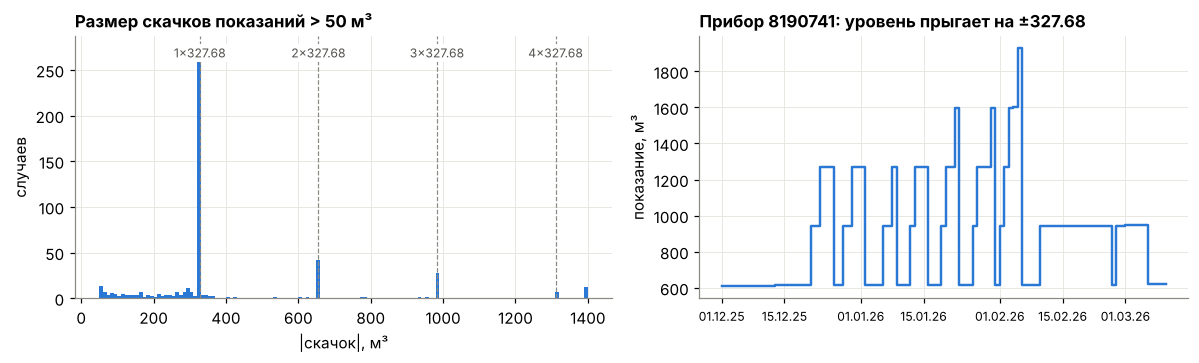

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw={'width_ratios': [1.1, 1]})
# слева: распределение размеров скачков — пики ровно на кратных 327.68
jumps = raw.loc[raw['diff'].abs() > 50, 'diff'].abs().clip(upper=1400)
axes[0].hist(jumps, bins=np.arange(50, 1401, 10), color=C_BLUE)
for kk in (1, 2, 3, 4):
    axes[0].axvline(kk * BIT_STEP, color=C_GRAY, lw=0.8, ls='--')
    axes[0].text(kk * BIT_STEP, axes[0].get_ylim()[1] * 0.92, f'{kk}×327.68', fontsize=8, ha='center', color='#52514e',
                 bbox=dict(facecolor='white', edgecolor='none', pad=1))
axes[0].set_title('Размер скачков показаний > 50 м³', loc='left'); axes[0].set_xlabel('|скачок|, м³'); axes[0].set_ylabel('случаев')
# справа: пример прибора
g = P[(P.anon_id == '8190741') & (P.data.between('2025-12-01', '2026-03-10'))]
axes[1].plot(g.data, g.pokazanie, color=C_BLUE, lw=1.6, drawstyle='steps-post')
axes[1].set_title('Прибор 8190741: уровень прыгает на ±327.68', loc='left'); axes[1].set_ylabel('показание, м³')
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%d.%m.%y')); axes[1].tick_params(axis='x', labelsize=8)
plt.tight_layout(); plt.show()

### Находка 2. Взрыв событий «магнит» в августе–сентябре 2026 и «слепой» тип AQUA2
* До февраля 2026 — около 100 событий в месяц, в сентябре — **19 000**. Расход при этом не упал (п.7) — это похоже на изменение прошивки/чувствительности датчика или логирования, а не на волну краж.
* У типа **AQUA2 нет ни одного события «магнит»** (0 из 391) — у них нет датчика или он не передаётся. Отсутствие событий у AQUA2 **не значит**, что магнита нет.
* Доля приборов с магнитом сильно зависит от базовой станции: **BS-09 — 56%, BS-07 — 7%**. Воры не живут «по станциям» — это ещё один признак технической природы большинства срабатываний.

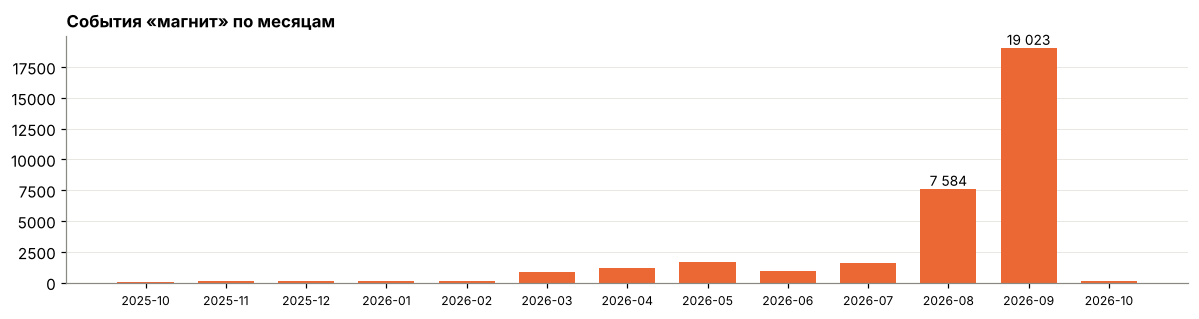

In [17]:
mm = S[S.sobytie == 'магнит'].groupby(S.data.dt.to_period('M')).size()
fig, ax = plt.subplots(figsize=(11, 3))
ax.bar(mm.index.astype(str), mm.values, color=C_ORANGE, width=0.7)
for i, v_ in enumerate(mm.values):
    if v_ > 5000: ax.text(i, v_, f'{v_:,}'.replace(',', ' '), ha='center', va='bottom', fontsize=9)
ax.grid(axis='x', visible=False); ax.set_title('События «магнит» по месяцам', loc='left'); ax.tick_params(axis='x', labelsize=8)
plt.tight_layout(); plt.show()

### Находка 3. Связь и «мёртвые» точки
* **98 приборов на связи почти весь год (≥ 300 дней), но не потребили и 100 литров** — пустые квартиры, перекрытые стояки или невключённые узлы. Ещё больше «почти мёртвых» среди тех, кто на связи меньше (всего 431 прибор с нулём ≥ 30 дней и < 100 л за всё время).
* **218 новых приборов на BS-02** появились одним днём — 26.09.2026 (подключили новый дом).
* Пропуски данных: в среднем у прибора нет **~20%** дней; хуже всего тип `aqua2_nvt_wa_stm` и станции BS-01/05/08 (~69% покрытия) — их стоит проверить по связи.

In [18]:
span = P.groupby('anon_id').agg(first=('data', 'min'), last=('data', 'max'), n=('data', 'size'))
span['pokrytie'] = span.n / ((span['last'] - span['first']).dt.days + 1)
span = span.join(dev)
dead = total.reindex(dev.index).fillna(0)
print(f'потребили < 100 л за весь год: {(dead < 0.1).sum()} приборов ({(dead < 0.1).mean():.0%}), из них на связи >= 300 дней: {((dead < 0.1) & (span.n.reindex(dev.index) >= 300)).sum()}')
print('новые приборы 26.09.2026:', (span['first'] == '2026-09-26').sum(), span[span['first'] == '2026-09-26'].bs.value_counts().to_dict())
print('\nпокрытие (доля дней с данными) по станциям:')
print(span.groupby('bs').pokrytie.mean().round(2).to_string())
print('\nпо типу:')
print(span.groupby('tip').pokrytie.mean().round(2).to_string())

потребили < 100 л за весь год: 912 приборов (30%), из них на связи >= 300 дней: 98
новые приборы 26.09.2026: 218 {'BS-02': 218}

покрытие (доля дней с данными) по станциям:
bs
BS-01    0.69
BS-02    0.90
BS-03    0.88
BS-04    0.71
BS-05    0.68
BS-06    0.80
BS-07    0.84
BS-08    0.69
BS-09    0.87
BS-10    0.75

по типу:
tip
AQUA2                 0.87
aqua2_nvt_wa_stm      0.73
aqua2_stm             0.82
aqua2set_fudan_stm    0.94


## Примеры аномалий на графиках

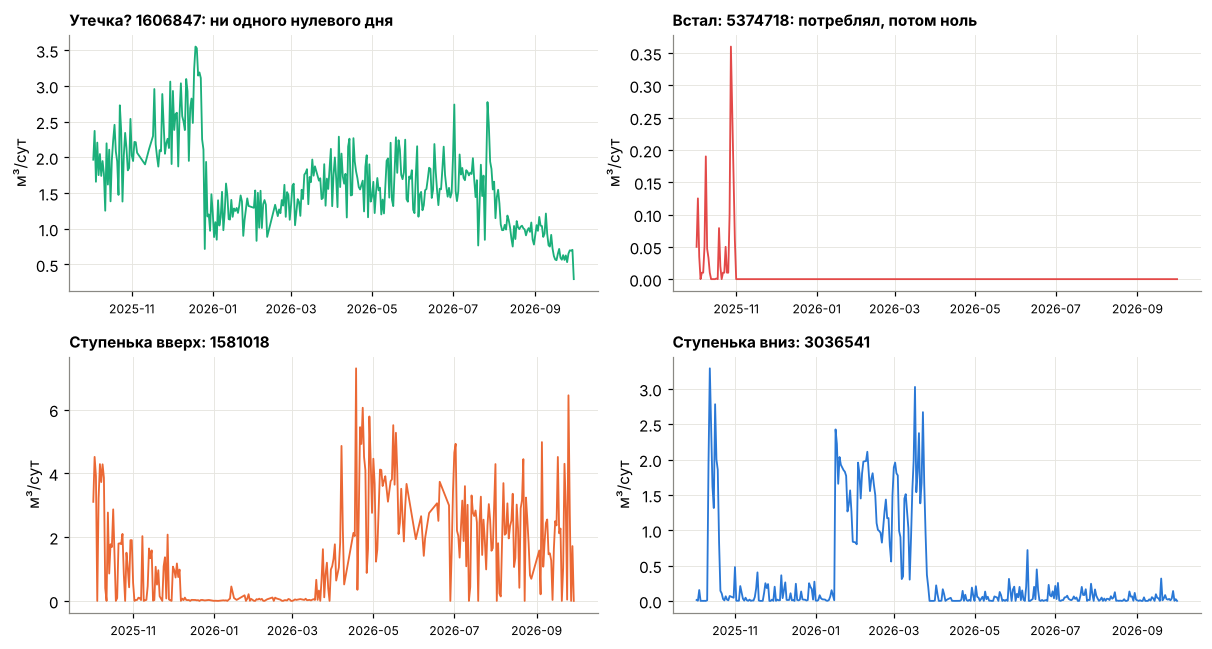

In [19]:
def show(ax, aid, title, color=C_BLUE):
    g = V[V.anon_id == aid]
    ax.plot(g.data, g.rate, color=color, lw=1.2)
    ax.set_title(title, loc='left', fontsize=10); ax.set_ylabel('м³/сут'); ax.tick_params(axis='x', labelsize=8)

ex_leak = leak_strong.sort_values('p5', ascending=False).index[0]
ex_zero = zero[zero.gruppa == 'потреблял, потом встал'].sort_values('days', ascending=False).index[0]
ex_up   = step[step.tip == 'рост N → kN'].sort_values('ratio', ascending=False).index[0]
ex_dn   = step[step.tip == 'падение N → N/k'].sort_values('half_ratio').index[0]  # подтверждается обоими методами
fig, axes = plt.subplots(2, 2, figsize=(11, 6))
show(axes[0, 0], ex_leak, f'Утечка? {ex_leak}: ни одного нулевого дня', C_AQUA)
show(axes[0, 1], ex_zero, f'Встал: {ex_zero}: потреблял, потом ноль', C_RED)
show(axes[1, 0], ex_up,   f'Ступенька вверх: {ex_up}', C_ORANGE)
show(axes[1, 1], ex_dn,   f'Ступенька вниз: {ex_dn}', C_BLUE)
plt.tight_layout(); plt.show()

## Итог: кого проверять в первую очередь

Баллы (чем выше, тем раньше на выезд):
* **+3** сильная утечка, которая идёт до сих пор (90+ дней без нуля и «пол» ≥ 50 л/сут) — прямые потери воды; **+1** если утечка была, но закончилась;
* **+3** при магните расход падает > 5 раз — вероятное вмешательство;
* **+2** потреблял, потом ≥ 60 суток ноль при живой связи — застрял/остановлен; **+2** если в это время был магнит;
* **+2** ступенька вниз (N → N/k или N → 0); **+2** если магнит был рядом с датой ступеньки (−30…+60 дней);
* **+1** ≥ 3 абсолютных всплеска.

Ошибки данных (битовая, x10, > 75 м³/сут) — **отдельный список в техподдержку**, на выезд не нужно.

In [20]:
score = pd.Series(0, index=dev.index, dtype=float)
why = {i: [] for i in dev.index}
def add(ids, pts, label):
    for i in ids:
        score[i] += pts; why[i].append(label)

stopped = zero[(zero.gruppa == 'потреблял, потом встал') & (zero.days >= 60)]
stopped_mag = [i for i, r in stopped.iterrows()
               if ((M.anon_id == i) & (M.data >= r.start - pd.Timedelta(days=7)) & (M.data <= r.end)).any()]
step_down = step[step.tip.isin(['падение N → N/k', 'N → 0 (выезд / прибор встал)'])]
last_day = P.data.max()
leak_now = leak_strong[leak_strong.end >= last_day - pd.Timedelta(days=14)]
add(leak_now.index, 3, 'утечка идёт сейчас')
add(leak_strong.index.difference(leak_now.index), 1, 'была утечка')
add(mag_drop.index, 3, 'падение при магните')
add(stopped.index, 2, 'встал (60+ дней ноль)')
add(stopped_mag, 2, 'встал + магнит')
add(step_down.index, 2, 'ступенька вниз')
# магнит рядом со ступенькой: от 30 дней до неё до 60 дней после
step_mag = [i for i, r in step_down.iterrows()
            if ((M.anon_id == i) & (M.data >= r.data_stupeni - pd.Timedelta(days=30)) & (M.data <= r.data_stupeni + pd.Timedelta(days=60))).any()]
add(step_mag, 2, 'ступенька вниз + магнит рядом')
sp_cnt = abs_sp.anon_id.value_counts()
add(sp_cnt[sp_cnt >= 3].index, 1, 'всплески')

tech = sorted(set(bit_ids) | set(unreal.anon_id) | set(x10.anon_id) | set(huge.anon_id) | err_ids)
TOP = (pd.DataFrame({'ball': score, 'prichiny': pd.Series({i: ', '.join(v) for i, v in why.items()})})
         .join(dev[['bs', 'tip']]).query('ball > 0').drop(index=tech, errors='ignore')  # ошибки данных — не на выезд
         .sort_values(['ball', 'prichiny'], ascending=False))
print(f'утечка идёт сейчас: {len(leak_now)} | встал >= 60 дней: {len(stopped)} (с магнитом: {len(stopped_mag)}) | ступенька вниз: {len(step_down)} (с магнитом рядом: {len(step_mag)})')
print('приборов с баллом > 0:', len(TOP), '| с баллом >= 4:', (TOP.ball >= 4).sum())
TOP.head(20)

утечка идёт сейчас: 41 | встал >= 60 дней: 106 (с магнитом: 3) | ступенька вниз: 95 (с магнитом рядом: 5)
приборов с баллом > 0: 362 | с баллом >= 4: 13


,ball,prichiny,bs,tip
8344936,7.0,"падение при магните, ступенька вниз, ступенька...",BS-06,aqua2_stm
7032675,7.0,"падение при магните, ступенька вниз, ступенька...",BS-09,aqua2_stm
8876485,4.0,"ступенька вниз, ступенька вниз + магнит рядом",BS-01,aqua2_stm
1781014,4.0,"ступенька вниз, ступенька вниз + магнит рядом",BS-03,aqua2_stm
5686440,4.0,"ступенька вниз, ступенька вниз + магнит рядом",BS-06,aqua2_stm
8625789,4.0,"встал (60+ дней ноль), ступенька вниз",BS-03,AQUA2
7801742,4.0,"встал (60+ дней ноль), ступенька вниз",BS-05,aqua2_stm
6529591,4.0,"встал (60+ дней ноль), ступенька вниз",BS-05,aqua2_stm
4982185,4.0,"встал (60+ дней ноль), ступенька вниз",BS-05,AQUA2
9302752,4.0,"встал (60+ дней ноль), ступенька вниз",BS-07,AQUA2


In [21]:
print(f'В техподдержку (ошибки данных, не вода): {len(tech)} приборов, из них AQUA2: {(dev.loc[tech].tip == "AQUA2").sum()}')
print(', '.join(tech[:20]), '...')

В техподдержку (ошибки данных, не вода): 61 приборов, из них AQUA2: 61
1023776, 1184793, 1423304, 1492831, 1698800, 1835380, 2030325, 2159987, 2351232, 2409777, 2491162, 2519659, 2569627, 2647530, 2665800, 2859628, 2983464, 3240435, 3281821, 3332300 ...


In [22]:
# сохраняем результаты
Out = Path('results'); Out.mkdir(exist_ok=True)
TOP.to_csv(Out/'na_proverku.csv', sep=';', encoding='utf-8-sig')
dev.loc[tech, ['bs', 'tip', 'model']].to_csv(Out/'v_tehpodderzhku.csv', sep=';', encoding='utf-8-sig')
print('сохранено: results/na_proverku.csv, results/v_tehpodderzhku.csv')

сохранено: results/na_proverku.csv, results/v_tehpodderzhku.csv
